# Notebook 4 — Evaluation: Significance, Regimes, Ablation & Uncertainty

**This notebook's job:** score the sealed test set (2023–2025) **once**, and answer:
- **H1:** does ML beat the econometric benchmarks?
- **H2:** does any advantage depend on the volatility regime?

Every claim comes with a significance test that respects the overlap in *h*-day targets.

| | |
|---|---|
| **Inputs** | `oos_forecasts.parquet`, `frozen_config.yaml`, `regimes.parquet`, `targets.parquet`, `features.parquet` |
| **Outputs** | `results/test_scorecard.csv`, `dm_tests.csv`, `mcs.csv`, `mincer_zarnowitz.csv`, `regime_losses.csv`, `stress_losses.csv`, `ablation.csv`, `shap_groups.csv`, `interval_calibration.csv`, `ensembles.parquet` |
| **Runtime** | about 2–4 min |

**Testing protocol**

| Question | Tool | Why this tool |
|---|---|---|
| Is model A more accurate than B? | Diebold-Mariano, HAC with 3*h* lags + fixed-*b* critical values | Overlapping targets make loss differentials MA(*h*−1). An iid test would reject ~68% of the time under the null; this one rejects ~5–6% (`tests/test_evaluation.py`) |
| Which models are statistically indistinguishable from the best? | Model Confidence Set (Hansen, Lunde & Nason 2011), 90% | Avoids cherry-picking one pairwise comparison |
| How uncertain is a loss ratio? | Stationary block bootstrap, block = 3*h* | Preserves time dependence |
| Is a forecast biased or just noisy? | Mincer-Zarnowitz regression, HAC | Separates bias (a ≠ 0, b ≠ 1) from noise (low R²) |

**Primary loss:** QLIKE on variance. MSE on variance is reported as a second robust loss (Patton 2011).

**Headline benchmark:** HAR-X, which is HAR plus implied variance (VIX²).

## 0. Setup

In [1]:
import os, sys, json, hashlib, platform, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "config.yaml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook from inside the repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from scipy import stats

from src.config import load_config
from src.data import acquire
from src import models as M
from src import evaluation as E
from src.metrics import qlike, se_var, summary
from src.validation import make_folds

cfg, P = load_config(ROOT)
H = cfg["targets"]["horizons"]
DATA_MODE = os.environ.get("VOLRES_DATA_MODE", "live")
sub = "_synthetic" if DATA_MODE == "synthetic" else ""
OUT = P.processed / sub if sub else P.processed
FIG = P.figures / sub if sub else P.figures
RES = P.results / sub if sub else P.results
for p in (FIG, RES):
    p.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4g}")
plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

def savefig(fig, name):
    fig.savefig(FIG / f"nb04_{name}.png", bbox_inches="tight", dpi=150)

BENCH = "HAR_X"
CORE = ["HistVol", "EWMA", "GARCH", "EGARCH", "GJR", "HAR", "HAR_X", "RF", "XGB"]
ENS_MEMBERS = ["GJR", "HAR_X", "RF", "XGB"]          # fixed before scoring: best of each family + both ML models
ENSEMBLES = ["ENS_EQ", "ENS_TRAIL", "ENS_REGIME"]
HEADLINE = CORE + ENSEMBLES
COLORS = {**{m: "#9a9a9a" for m in ["HistVol", "EWMA"]}, **{m: "tab:blue" for m in ["GARCH", "EGARCH", "GJR"]},
          **{m: "tab:green" for m in ["HAR", "HAR_X"]}, **{m: "tab:red" for m in ["RF", "XGB"]},
          **{m: "tab:purple" for m in ENSEMBLES}}
SEED = cfg["project"]["seed"]
if DATA_MODE == "synthetic":
    print("=" * 72 + "\nSYNTHETIC MODE: pipeline test only. These numbers are NOT research results.\n" + "=" * 72)

## 1. Load inputs, verify provenance, log this scoring event

Every time the test set is scored, a row is appended to `results/test_scoring_log.csv` with the frozen-configuration hash.

- If the log ever shows **more than one distinct configuration hash**, the test set has been used to compare configurations. In that case, report it, and treat the results as partly in-sample.
- One hash scored several times, for example after rerunning this notebook, is fine.

In [2]:
meta1 = json.loads((OUT / "nb01_meta.json").read_text())
meta3 = json.loads((OUT / "nb03_meta.json").read_text())
for name in ("oos_forecasts.parquet", "frozen_config.yaml", "regimes.parquet"):
    assert acquire.sha256(OUT / name) == meta3["outputs_sha256"][name], f"{name} changed since Notebook 3"
assert acquire.sha256(OUT / "targets.parquet") == meta1["outputs_sha256"]["targets.parquet"]
FROZEN_HASH = hashlib.sha256((OUT / "frozen_config.yaml").read_text().encode()).hexdigest()
assert FROZEN_HASH == meta3["frozen_config_sha256"]
frozen = yaml.safe_load((OUT / "frozen_config.yaml").read_text())

fc = pd.read_parquet(OUT / "oos_forecasts.parquet")
targets = pd.read_parquet(OUT / "targets.parquet")
regimes = pd.read_parquet(OUT / "regimes.parquet").drop_duplicates("date").set_index("date")["regime"]
X = pd.read_parquet(OUT / "features.parquet")
panel = pd.read_parquet(OUT / "panel.parquet")
catalog = pd.read_csv(OUT / "feature_catalog.csv", index_col=0)
feature_sets = json.loads((OUT / "feature_sets.json").read_text())

log_path = RES / "test_scoring_log.csv"
entry = pd.DataFrame([{"scored_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),
                       "frozen_config_sha256": FROZEN_HASH,
                       "forecasts_sha256": meta3["outputs_sha256"]["oos_forecasts.parquet"]}])
scoring_log = pd.concat([pd.read_csv(log_path), entry]) if log_path.exists() else entry
scoring_log.to_csv(log_path, index=False)
n_configs = scoring_log["frozen_config_sha256"].nunique()
print(f"frozen config {FROZEN_HASH[:16]} | test scored {len(scoring_log)} time(s) under {n_configs} configuration(s)")
if n_configs > 1:
    print("WARNING: the test set has been scored under more than one configuration. Disclose this in the report.")

frozen config 2d139937c8523977 | test scored 1 time(s) under 1 configuration(s)


## 2. Assemble forecasts and build the ensembles

The three combinations of GJR, HAR-X, RF and XGB use **only losses already known at t**. A forecast's loss is known *h* sessions after it was made. Their member list and settings were fixed before scoring:

| Ensemble | Weights |
|---|---|
| ENS_EQ | Equal weights. Often hard to beat (the "forecast combination puzzle") |
| ENS_TRAIL | ∝ 1 / trailing 126-day mean QLIKE |
| ENS_REGIME | ∝ 1 / mean past QLIKE in **today's** volatility regime (the regime-adaptive ensemble from the research plan) |

Ensembles run continuously from 2019. Their test-period weights therefore start from validation-period track records, as they would in live use.

In [3]:
W, RV, SPLIT, ens_weights = {}, {}, {}, {}
for h in H:
    w = fc[fc.horizon == h].pivot(index="date", columns="model", values="forecast").sort_index()
    rv = targets.loc[w.index, f"rv_var_{h}"]
    ens = E.combine(w[ENS_MEMBERS], rv, h, window=126, regimes=regimes)
    for k in ENSEMBLES:
        w[k] = ens[k]
    ens_weights[h] = {"trail": ens["_weights_trail"], "regime": ens["_weights_regime"]}
    W[h], RV[h] = w, rv
    SPLIT[h] = fc[fc.horizon == h].drop_duplicates("date").set_index("date")["split"].reindex(w.index)

POINT = [m for m in W[H[0]].columns if not m.startswith("QGB_")]
test = {h: SPLIT[h] == "test" for h in H}
LOSS = {h: pd.DataFrame({m: qlike(RV[h], W[h][m]) for m in POINT}, index=W[h].index) for h in H}
LOSS_MSE = {h: pd.DataFrame({m: se_var(RV[h], W[h][m]) for m in POINT}, index=W[h].index) for h in H}
pd.concat({h: W[h][ENSEMBLES] for h in H}, names=["horizon"]).to_parquet(OUT / "ensembles.parquet")
print({h: f"{int(test[h].sum())} test days, {int((~test[h]).sum())} validation days" for h in H})

{5: '752 test days, 1008 validation days', 20: '752 test days, 1008 validation days'}


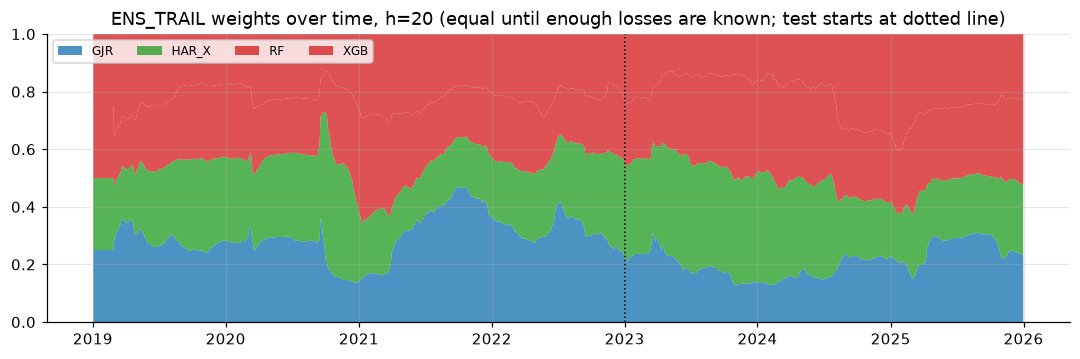

In [4]:
h = H[-1]
wt = ens_weights[h]["trail"]
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.stackplot(wt.index, wt.T.values, labels=wt.columns, colors=[COLORS[m] for m in wt.columns], alpha=0.8)
ax.axvline(pd.Timestamp(cfg["splits"]["test_start"]), color="k", ls=":", lw=1)
ax.set_ylim(0, 1); ax.legend(loc="upper left", ncol=4, fontsize=8)
ax.set_title(f"ENS_TRAIL weights over time, h={h} (equal until enough losses are known; test starts at dotted line)")
savefig(fig, "ensemble_weights"); plt.show()

## 3. Headline: test-set scorecard (2023–2025)

The columns are:
- **QLIKE:** the primary loss.
- **QLIKE vs HAR-X:** a ratio below 1 is better. The 95% interval comes from a stationary block bootstrap.
- **R²<sub>OOS</sub>:** the share of HAR-X's (or EWMA's) squared variance error that the model removes. A positive value is better.
- **bias:** mean forecast volatility minus realised volatility, in vol points.

In [5]:
score_rows = []
for h in H:
    L, Lm, t = LOSS[h], LOSS_MSE[h], test[h]
    for m in [x for x in HEADLINE if x in L]:
        s = summary(RV[h][t], W[h].loc[t, m])
        ratio, lo, hi = E.bootstrap_ratio_ci(L.loc[t, m], L.loc[t, BENCH], block=3 * h, reps=2000, seed=SEED)
        score_rows.append({"horizon": h, "model": m, "QLIKE": s["QLIKE"], "QLIKE_vs_HARX": ratio,
                           "ci_lo": lo, "ci_hi": hi, "MSE_var": s["MSE_var"], "RMSE_vol": s["RMSE_vol"],
                           "MAE_vol": s["MAE_vol"], "bias_vol": s["bias_vol"],
                           "R2oos_vs_HARX": 1 - Lm.loc[t, m].sum() / Lm.loc[t, BENCH].sum(),
                           "R2oos_vs_EWMA": 1 - Lm.loc[t, m].sum() / Lm.loc[t, "EWMA"].sum()})
scorecard = pd.DataFrame(score_rows)
scorecard.to_csv(RES / "test_scorecard.csv", index=False)
for h in H:
    print(f"\n=== h = {h} (test, n = {int(test[h].sum())}) ===")
    display(scorecard[scorecard.horizon == h].drop(columns="horizon").set_index("model").sort_values("QLIKE"))


=== h = 5 (test, n = 752) ===


,QLIKE,QLIKE_vs_HARX,ci_lo,ci_hi,MSE_var,RMSE_vol,MAE_vol,bias_vol,R2oos_vs_HARX,R2oos_vs_EWMA
model,,,,,,,,,,
XGB,0.3113,0.8938,0.7828,1.044,0.002571,0.06528,0.04064,0.006984,-0.01647,0.3224
ENS_EQ,0.3157,0.9063,0.8285,0.9997,0.002635,0.0662,0.04109,0.008777,-0.04193,0.3054
ENS_TRAIL,0.3158,0.9066,0.8287,1,0.00265,0.06625,0.04102,0.008523,-0.04762,0.3016
ENS_REGIME,0.3168,0.9094,0.8304,1.001,0.002613,0.06598,0.04098,0.008549,-0.03321,0.3112
RF,0.3303,0.9483,0.845,1.071,0.003292,0.0702,0.04183,0.007002,-0.3015,0.1324
HAR_X,0.3483,1,1,1,0.002529,0.06557,0.04055,0.002342,0,0.3333
GJR,0.3622,1.04,0.9063,1.205,0.002613,0.07086,0.04586,0.01577,-0.03296,0.3114
EGARCH,0.3733,1.072,0.9357,1.242,0.002716,0.06911,0.04512,0.01397,-0.07367,0.2842
GARCH,0.4056,1.164,1.017,1.335,0.003983,0.08147,0.05028,0.01965,-0.5747,-0.04981



=== h = 20 (test, n = 752) ===


,QLIKE,QLIKE_vs_HARX,ci_lo,ci_hi,MSE_var,RMSE_vol,MAE_vol,bias_vol,R2oos_vs_HARX,R2oos_vs_EWMA
model,,,,,,,,,,
ENS_EQ,0.2303,0.8392,0.762,1.11,0.001364,0.06185,0.03638,0.00813,-0.02725,0.3407
ENS_TRAIL,0.2319,0.845,0.7806,1.064,0.001377,0.06197,0.03585,0.00641,-0.03726,0.3343
ENS_REGIME,0.2344,0.8541,0.7767,1.151,0.001369,0.06223,0.037,0.008921,-0.03102,0.3383
RF,0.236,0.8601,0.8225,0.9776,0.001299,0.06018,0.034,0.0004782,0.02195,0.3723
XGB,0.2504,0.9127,0.7564,1.476,0.00161,0.066,0.04018,0.01051,-0.2123,0.222
GJR,0.2534,0.9235,0.7543,1.607,0.001722,0.06928,0.04444,0.01766,-0.2965,0.1679
EGARCH,0.2629,0.9583,0.7378,1.712,0.001281,0.06373,0.04211,0.01352,0.03566,0.3811
HAR_X,0.2744,1,1,1,0.001328,0.06201,0.03424,-0.0001197,0,0.3582
HAR,0.2813,1.025,0.9215,1.412,0.001395,0.06477,0.0401,0.004816,-0.05032,0.3259


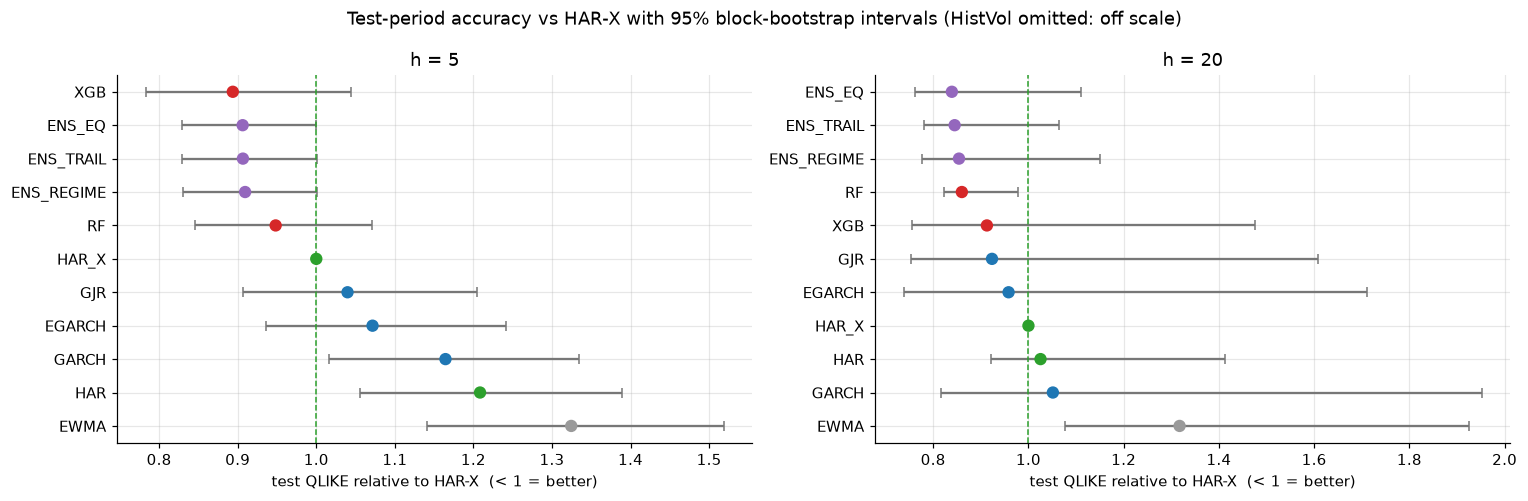

In [6]:
fig, axes = plt.subplots(1, len(H), figsize=(7 * len(H), 4.6))   # no sharey: each panel has its own model order
for ax, h in zip(np.atleast_1d(axes), H):
    s = scorecard[scorecard.horizon == h].set_index("model").loc[[m for m in HEADLINE if m != "HistVol"]]
    s = s.sort_values("QLIKE_vs_HARX", ascending=False)
    y = np.arange(len(s))
    ax.errorbar(s.QLIKE_vs_HARX, y, xerr=[s.QLIKE_vs_HARX - s.ci_lo, s.ci_hi - s.QLIKE_vs_HARX],
                fmt="none", ecolor="#777", capsize=3)
    ax.scatter(s.QLIKE_vs_HARX, y, c=[COLORS[m] for m in s.index], s=50, zorder=3)
    ax.axvline(1, color="tab:green", ls="--", lw=1)
    ax.set_yticks(y, s.index); ax.set_xlabel("test QLIKE relative to HAR-X  (< 1 = better)")
    ax.set_title(f"h = {h}")
fig.suptitle("Test-period accuracy vs HAR-X with 95% block-bootstrap intervals (HistVol omitted: off scale)")
fig.tight_layout(); savefig(fig, "forest_vs_harx"); plt.show()

## 4. Significance

### 4.1 Diebold-Mariano: every model vs HAR-X

A negative `mean_diff` with p < 0.05 means the model beats HAR-X. A positive one with p < 0.05 means it is worse.

In [7]:
dm_all = []
for h in H:
    t = test[h]
    for loss_name, Lset in [("QLIKE", LOSS), ("MSE_var", LOSS_MSE)]:
        d = E.dm_table(Lset[h].loc[t, [m for m in HEADLINE if m in Lset[h]]], BENCH, h)
        d.insert(0, "loss", loss_name); d.insert(0, "horizon", h)
        dm_all.append(d.reset_index(names="model"))
dm_all = pd.concat(dm_all, ignore_index=True)
for h in H:
    print(f"\n=== h = {h}, QLIKE ===")
    display(dm_all[(dm_all.horizon == h) & (dm_all.loss == "QLIKE")].drop(columns=["horizon", "loss"]).set_index("model"))


=== h = 5, QLIKE ===


,mean_diff,dm_stat,p_value,n,hac_lags,loss_ratio,verdict
model,,,,,,,
XGB,-0.03701,-1.259,0.2081,752,15,0.8938,no significant difference
ENS_EQ,-0.03265,-1.559,0.119,752,15,0.9063,no significant difference
ENS_TRAIL,-0.03252,-1.568,0.1168,752,15,0.9066,no significant difference
ENS_REGIME,-0.03155,-1.533,0.1254,752,15,0.9094,no significant difference
RF,-0.01801,-0.7704,0.4411,752,15,0.9483,no significant difference
GJR,0.01385,0.4735,0.6358,752,15,1.04,no significant difference
EGARCH,0.02494,0.8719,0.3832,752,15,1.072,no significant difference
GARCH,0.05727,1.958,0.05019,752,15,1.164,no significant difference
HAR,0.0726,2.314,0.02067,752,15,1.208,worse than HAR_X



=== h = 20, QLIKE ===


,mean_diff,dm_stat,p_value,n,hac_lags,loss_ratio,verdict
model,,,,,,,
ENS_EQ,-0.04413,-1.247,0.2124,752,60,0.8392,no significant difference
ENS_TRAIL,-0.04253,-1.354,0.1758,752,60,0.845,no significant difference
ENS_REGIME,-0.04002,-1.138,0.2551,752,60,0.8541,no significant difference
RF,-0.03838,-1.506,0.1319,752,60,0.8601,no significant difference
XGB,-0.02394,-0.581,0.5613,752,60,0.9127,no significant difference
GJR,-0.021,-0.3615,0.7178,752,60,0.9235,no significant difference
EGARCH,-0.01145,-0.1767,0.8597,752,60,0.9583,no significant difference
HAR,0.006958,0.2756,0.7829,752,60,1.025,no significant difference
GARCH,0.01407,0.2439,0.8073,752,60,1.051,no significant difference


### 4.2 The specific comparisons behind H1

In [8]:
PAIRS = [("XGB", "HAR_X"), ("RF", "HAR_X"), ("XGB", "GJR"), ("XGB", "GARCH"), ("XGB", "EGARCH"),
         ("XGB", "RF"), ("HAR_X", "GJR"), ("HAR_X", "HAR"), ("ENS_REGIME", "ENS_EQ"), ("ENS_EQ", "HAR_X"),
         ("ENS_REGIME", "HAR_X")]
pair_rows = []
for h in H:
    t = test[h]
    for a, b in PAIRS:
        r = E.diebold_mariano(LOSS[h].loc[t, a], LOSS[h].loc[t, b], h)
        pair_rows.append({"horizon": h, "comparison": f"{a} vs {b}",
                          "QLIKE_ratio": LOSS[h].loc[t, a].mean() / LOSS[h].loc[t, b].mean(), **r})
pairs = pd.DataFrame(pair_rows)
pairs["result"] = np.select([(pairs.p_value < 0.05) & (pairs.mean_diff < 0), (pairs.p_value < 0.05) & (pairs.mean_diff > 0)],
                            ["first significantly better", "first significantly worse"], "not significant")
pairs.pivot(index="comparison", columns="horizon", values=["QLIKE_ratio", "p_value", "result"])

QLIKE_ratio         p_value                               result                           
horizon                       5      20       5        20                          5                          20
comparison                                                                                                      
ENS_EQ vs HAR_X           0.9063 0.8392    0.119   0.2124             not significant            not significant
ENS_REGIME vs ENS_EQ       1.004  1.018   0.4328 0.001802             not significant  first significantly worse
ENS_REGIME vs HAR_X       0.9094 0.8541   0.1254   0.2551             not significant            not significant
HAR_X vs GJR              0.9617  1.083   0.6358   0.7178             not significant            not significant
HAR_X vs HAR              0.8275 0.9753  0.02067   0.7829  first significantly better            not significant
RF vs HAR_X               0.9483 0.8601   0.4411   0.1319             not significant            not significant
XGB vs EGARCH              0.834 0.9525  0.04155   0.7859  first significantly better            not significant
XGB vs GARCH              0.7676 0.8682 0.009309   0.2694  first significantly better            not significant
XGB vs GJR                0.8596 0.9884  0.04323   0.9318  first significantly better            not significant
XGB vs HAR_X              0.8938 0.9127   0.2081   0.5613             not significant            not significant
XGB vs RF                 0.9425  1.061   0.1843   0.5263             not significant            not significant

### 4.3 Model Confidence Set (90%)

The MCS is the set of models that cannot be statistically distinguished from the best, after accounting for testing many models at once. It runs on QLIKE and on MSE-var separately: a model that survives both is robustly competitive.

In [9]:
mcs_rows = []
for h in H:
    t = test[h]
    cand = [m for m in HEADLINE if m in LOSS[h]]
    for loss_name, Lset in [("QLIKE", LOSS), ("MSE_var", LOSS_MSE)]:
        Lt = Lset[h].loc[t, cand]
        if loss_name == "MSE_var":
            Lt = Lt * 1e4                                    # rescale only for numerical stability
        r = E.model_confidence_set(Lt, alpha=0.10, block=3 * h, reps=2000, seed=SEED)
        r.insert(0, "loss", loss_name); r.insert(0, "horizon", h)
        mcs_rows.append(r.reset_index(names="model"))
mcs = pd.concat(mcs_rows, ignore_index=True)
mcs_view = mcs.pivot_table(index="model", columns=["horizon", "loss"], values="in_MCS", aggfunc="first")
mcs_view = mcs_view.loc[[m for m in HEADLINE if m in mcs_view.index]]
mcs_view.replace({True: "✓", False: ""})

horizon         5             20      
loss       MSE_var QLIKE MSE_var QLIKE
model                                 
HistVol          ✓             ✓      
EWMA             ✓             ✓      
GARCH            ✓             ✓      
EGARCH           ✓             ✓     ✓
GJR              ✓             ✓     ✓
HAR              ✓             ✓      
HAR_X            ✓     ✓       ✓     ✓
RF               ✓     ✓       ✓     ✓
XGB              ✓     ✓       ✓     ✓
ENS_EQ           ✓     ✓       ✓     ✓
ENS_TRAIL        ✓     ✓       ✓     ✓
ENS_REGIME       ✓     ✓

### 4.4 Mincer-Zarnowitz: bias versus noise

The table regresses realised variance on the forecast. A well-calibrated forecast has a = 0 and b = 1:
- **b < 1:** the forecast over-reacts. High forecasts are too high and low ones too low.
- **b > 1:** the forecast under-reacts.

The log-space version is less dominated by a few crisis days.

In [10]:
mz_rows = []
for h in H:
    t = test[h]
    for m in [x for x in HEADLINE if x in W[h]]:
        for space in (False, True):
            r = E.mincer_zarnowitz(RV[h][t], W[h].loc[t, m], h, log_space=space)
            mz_rows.append({"horizon": h, "model": m, "space": "log" if space else "level", **r})
mz = pd.DataFrame(mz_rows)
mz.pivot_table(index="model", columns=["horizon", "space"], values=["b", "R2"]).loc[[m for m in HEADLINE if m in W[H[0]]]]

R2                            b                     
horizon         5              20            5             20       
space        level    log   level    log  level    log  level    log
model                                                               
HistVol      0.115  0.152 0.03813 0.1389 0.3392 0.3898 0.1955 0.3719
EWMA       0.06598 0.1299 0.03707 0.1065 0.5006 0.5372 0.2397 0.3611
GARCH        0.121 0.2082 0.05836 0.1858 0.4595 0.6674 0.2087 0.5402
EGARCH      0.3019 0.2942  0.1763 0.2314  1.317 0.7676  0.888 0.6327
GJR         0.3169 0.3015  0.1365 0.2698 0.8957 0.7422 0.4304 0.6332
HAR         0.1327 0.1725  0.1033 0.1621 0.9922 0.6916 0.9248 0.6543
HAR_X       0.3773 0.2827  0.1514 0.2503  1.486 0.8313  1.073  0.773
RF          0.1919   0.35    0.17  0.307 0.6427 0.8016  1.107 0.8645
XGB         0.3244 0.3899  0.1218 0.2612 0.9304 0.8054 0.4651 0.6758
ENS_EQ      0.3058 0.3573  0.1502 0.3195 0.9748 0.8554 0.6875  0.843
ENS_TRAIL   0.3023 0.3588  0.1456 0.3143 0.9636 0.8546 0.6724 0.8225
ENS_REGIME  0.3115 0.3597  0.1483 0.3126  1.007 0.8568  0.681 0.8295

## 5. Stability: test loss by calendar year

,horizon,HistVol,EWMA,GARCH,EGARCH,GJR,HAR,HAR_X,RF,XGB,ENS_EQ,ENS_TRAIL,ENS_REGIME
year,,,,,,,,,,,,,
2023,5,0.5786,0.2309,0.2492,0.2412,0.2368,0.2441,0.2041,0.2152,0.2106,0.2004,0.2,0.202
2024,5,0.8085,0.4097,0.3715,0.339,0.3411,0.394,0.3537,0.3255,0.3359,0.3125,0.3142,0.3122
2025,5,1.133,0.7439,0.5964,0.5398,0.5088,0.6249,0.4871,0.4503,0.3873,0.4342,0.4332,0.4362
2023,20,0.08933,0.08146,0.1368,0.1057,0.1074,0.08271,0.04547,0.05445,0.1191,0.06901,0.06151,0.07301
2024,20,0.4816,0.3216,0.2393,0.2522,0.2193,0.2272,0.2135,0.1748,0.134,0.1503,0.1538,0.1569
2025,20,0.6254,0.6816,0.4897,0.4309,0.4337,0.5345,0.5647,0.4792,0.4991,0.4721,0.4809,0.4738


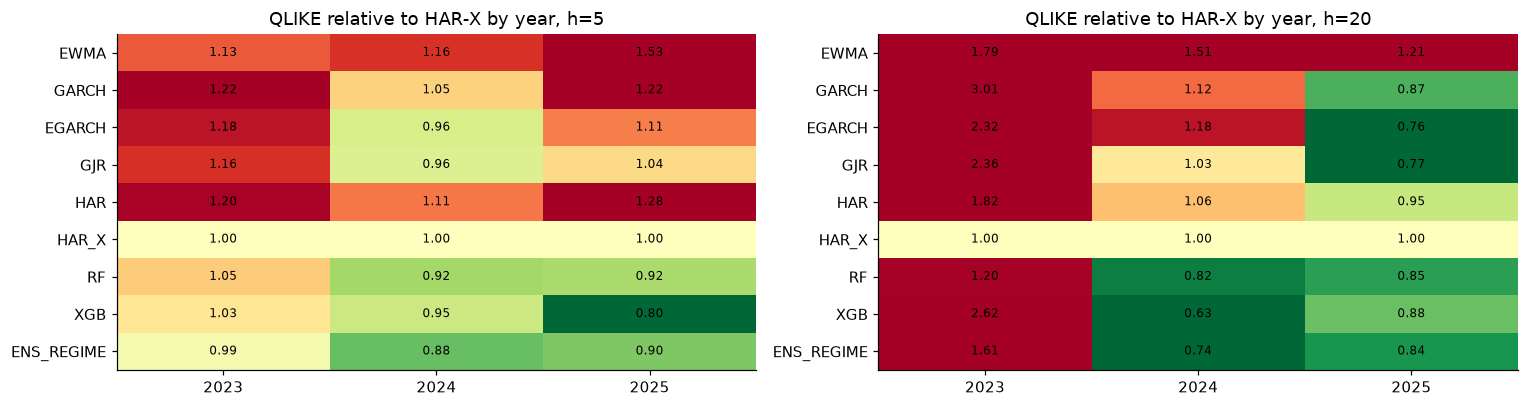

In [11]:
year_rows = []
for h in H:
    t = test[h]
    L = LOSS[h].loc[t, [m for m in HEADLINE if m in LOSS[h]]]
    by = L.groupby(L.index.year).mean()
    by.insert(0, "horizon", h)
    year_rows.append(by)
by_year = pd.concat(year_rows)
by_year.index.name = "year"
display(by_year)

fig, axes = plt.subplots(1, len(H), figsize=(7 * len(H), 3.8))
for ax, h in zip(np.atleast_1d(axes), H):
    b = by_year[by_year.horizon == h].drop(columns="horizon")[[m for m in CORE if m != "HistVol"] + ["ENS_REGIME"]]
    rel = b.div(b[BENCH], axis=0)
    im = ax.imshow(rel.T, cmap="RdYlGn_r", vmin=0.8, vmax=1.2, aspect="auto")
    ax.set_xticks(range(len(rel)), rel.index); ax.set_yticks(range(rel.shape[1]), rel.columns)
    for i in range(rel.shape[0]):
        for j in range(rel.shape[1]):
            ax.text(i, j, f"{rel.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"QLIKE relative to HAR-X by year, h={h}"); ax.grid(False)
fig.tight_layout(); savefig(fig, "by_year"); plt.show()

## 6. H2: performance by volatility regime

Each test day is labelled low, mid or high volatility from trailing 20-day realised variance, using thresholds estimated on that fold's training data (Notebook 3).

**The formal H2 test** is one joint Wald test of whether the XGB−HAR-X loss differential has the same mean in all three regimes. It uses regime dummies with HAC covariance. One joint test avoids the multiple-testing problem of declaring H2 supported because one of three per-regime tests happens to be significant. The per-regime DM tests are shown for description.

Validation-period regimes are shown separately as supporting evidence. Remember the ML models were tuned on those years.

XGB/HAR_X  dm_stat  p_value    n
horizon split regime                                  
5       test  low        0.9676  -0.2625   0.7929  162
              mid        0.9136   -1.035   0.3005  470
              high       0.7905  -0.8265   0.4085  120
        val   low        0.8672  -0.7031    0.482  111
              mid        0.8231   -1.486   0.1374  284
              high        1.268   0.7495   0.4535  613
20      test  low        0.6459  -0.6434     0.52  162
              mid         1.245     1.32   0.1868  470
        val   mid         1.033    0.315   0.7528  284
              high        1.333    1.233   0.2176  613

Joint test: is the XGB minus HAR-X QLIKE differential the same in every regime?


mean_diff_high  mean_diff_low  mean_diff_mid  wald_stat  p_value(equal across regimes)
horizon split                                                                                        
5       test          -0.1312       -0.01496       -0.02056     0.7062                         0.7025
        val              0.12       -0.06352        -0.1027      1.703                         0.4267
20      test          -0.1431       -0.08871        0.02879      3.269                         0.1951
        val            0.2417         0.1204        0.02336      1.866                         0.3933

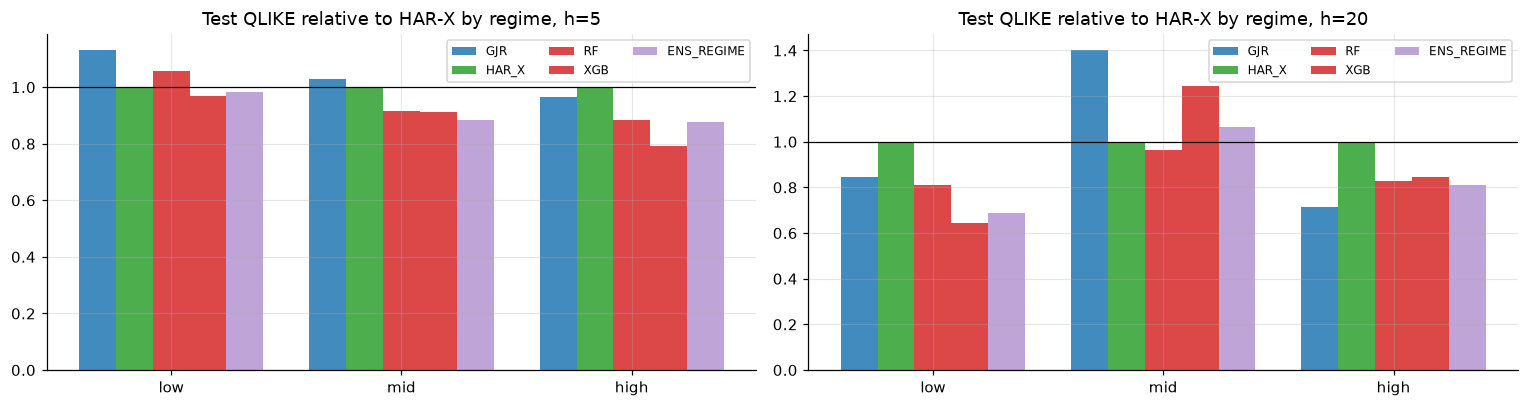

In [12]:
reg_rows, reg_dm = [], []
for h in H:
    for split in ("test", "val"):
        mask = SPLIT[h] == split
        L = LOSS[h].loc[mask, [m for m in HEADLINE if m in LOSS[h]]]
        rg = regimes.reindex(L.index)
        g = L.groupby(rg).mean().reindex(["low", "mid", "high"])
        g["n_days"] = rg.value_counts().reindex(g.index)
        g.insert(0, "split", split); g.insert(0, "horizon", h)
        reg_rows.append(g.reset_index(names="regime"))
        for r in ["low", "mid", "high"]:
            sel = rg == r
            if sel.sum() > 6 * h:
                d = E.diebold_mariano(L.loc[sel, "XGB"], L.loc[sel, BENCH], h)
                reg_dm.append({"horizon": h, "split": split, "regime": r,
                               "XGB/HAR_X": L.loc[sel, "XGB"].mean() / L.loc[sel, BENCH].mean(), **d})
regime_losses = pd.concat(reg_rows, ignore_index=True)
regime_dm = pd.DataFrame(reg_dm)
display(regime_dm.set_index(["horizon", "split", "regime"])[["XGB/HAR_X", "dm_stat", "p_value", "n"]])

h2_rows = []
for h in H:
    for split in ("test", "val"):
        mask = SPLIT[h] == split
        dlt = LOSS[h].loc[mask, "XGB"] - LOSS[h].loc[mask, BENCH]
        r = E.regime_difference_test(dlt, regimes.reindex(dlt.index), h)
        h2_rows.append({"horizon": h, "split": split, **{f"mean_diff_{k}": v for k, v in r["means"].items()},
                        "wald_stat": r["wald_stat"], "p_value(equal across regimes)": r["p_value"]})
h2_test = pd.DataFrame(h2_rows).set_index(["horizon", "split"])
print("Joint test: is the XGB minus HAR-X QLIKE differential the same in every regime?")
display(h2_test)

fig, axes = plt.subplots(1, len(H), figsize=(7 * len(H), 3.8), sharey=False)
show = ["GJR", "HAR_X", "RF", "XGB", "ENS_REGIME"]
for ax, h in zip(np.atleast_1d(axes), H):
    g = regime_losses[(regime_losses.horizon == h) & (regime_losses.split == "test")].set_index("regime")[show]
    rel = g.div(g[BENCH], axis=0)
    x = np.arange(len(rel)); wdt = 0.16
    for i, m in enumerate(show):
        ax.bar(x + (i - 2) * wdt, rel[m], wdt, label=m, color=COLORS[m], alpha=0.85 if m != "ENS_REGIME" else 0.6)
    ax.axhline(1, color="k", lw=0.8); ax.set_xticks(x, rel.index)
    ax.set_title(f"Test QLIKE relative to HAR-X by regime, h={h}"); ax.legend(fontsize=8, ncol=3)
fig.tight_layout(); savefig(fig, "regimes"); plt.show()

## 7. Stress windows

Each window covers forecasts issued shortly before and during a volatility event, so the forecast windows overlap the shock. The two validation windows are in-sample for tuning and are marked as such.

In [13]:
STRESS = {
    "COVID crash [val]": ("2020-02-10", "2020-04-30"),
    "2022 rate-hike bear [val]": ("2022-01-03", "2022-10-31"),
    "SVB / regional banks [test]": ("2023-02-27", "2023-04-14"),
    "Yen carry unwind [test]": ("2024-07-15", "2024-08-30"),
    "Tariff shock [test]": ("2025-03-17", "2025-05-16"),
}
stress_rows = []
for h in H:
    for name, (a, b) in STRESS.items():
        L = LOSS[h].loc[a:b, [m for m in HEADLINE if m in LOSS[h]]]
        if len(L) == 0:
            continue
        row = L.mean().div(L[BENCH].mean())
        row["n_days"] = len(L); row["window"] = name; row["horizon"] = h
        row["best"] = L.mean().idxmin()
        stress_rows.append(row)
stress = pd.DataFrame(stress_rows).set_index(["horizon", "window"])
print("QLIKE relative to HAR-X inside each window (< 1 = better than HAR-X)")
stress[[c for c in ["GARCH", "GJR", "EGARCH", "HAR", "RF", "XGB", "ENS_EQ", "ENS_REGIME", "best", "n_days"] if c in stress]]

QLIKE relative to HAR-X inside each window (< 1 = better than HAR-X)


GARCH    GJR  EGARCH    HAR     RF    XGB  ENS_EQ  ENS_REGIME    best  n_days
horizon window                                                                                                    
5       COVID crash [val]            1.018 0.9634   1.239  1.723  2.946   2.94   1.056       1.074     GJR      57
        2022 rate-hike bear [val]    1.254  1.416   1.169  1.181  1.163  1.185   1.046       1.033   HAR_X     209
        SVB / regional banks [test]  1.079 0.8657  0.8988  1.139 0.7168 0.7682  0.8023       0.793      RF      34
        Yen carry unwind [test]     0.5676 0.5081  0.5197 0.6876   0.52  0.624  0.5738      0.5638     GJR      35
        Tariff shock [test]          1.197 0.8914  0.8954  1.161 0.8607 0.7208  0.8232      0.8346     XGB      44
20      COVID crash [val]           0.9132  1.017   1.197  1.256  1.557  1.259   1.018        1.03   GARCH      57
        2022 rate-hike bear [val]   0.6381 0.8711  0.7716   1.06  1.454  1.358   0.855      0.8387   GARCH     209
        SVB / regional banks [test]  1.551  1.502   1.345 0.9613  1.208  2.313   1.435       1.417     HAR      34
        Yen carry unwind [test]     0.5821 0.5306  0.6088 0.7554 0.9569  0.586  0.5647      0.5395     GJR      35
        Tariff shock [test]         0.7458 0.6911   0.616 0.8368 0.8155 0.7814  0.7927      0.7983  EGARCH      44

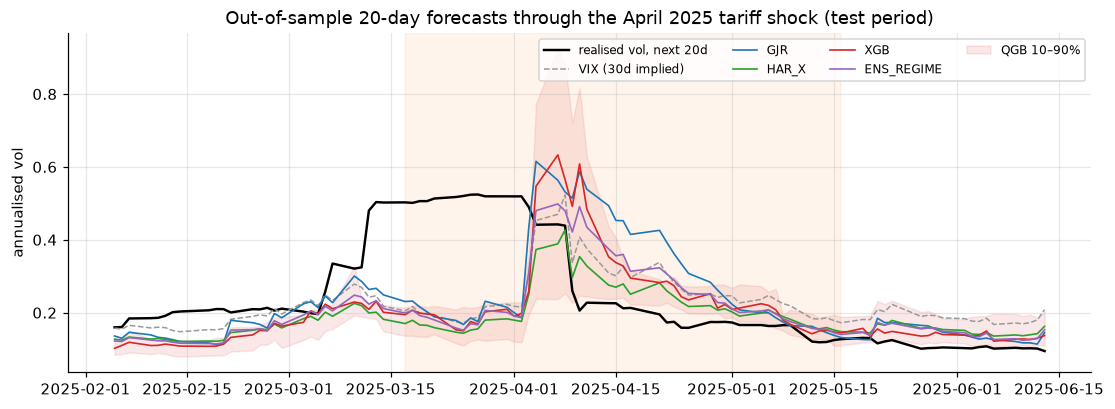

In [14]:
h = H[-1]
a, b = STRESS["Tariff shock [test]"]
a_plot, b_plot = pd.Timestamp(a) - pd.Timedelta(days=40), pd.Timestamp(b) + pd.Timedelta(days=30)
w = W[h].loc[a_plot:b_plot]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(w.index, np.sqrt(RV[h].loc[w.index]), "k", lw=1.6, label=f"realised vol, next {h}d")
ax.plot(w.index, np.sqrt(panel.loc[w.index, "vix_var"]), color="#999", lw=1, ls="--", label="VIX (30d implied)")
for m in ["GJR", "HAR_X", "XGB", "ENS_REGIME"]:
    ax.plot(w.index, np.sqrt(w[m]), lw=1.1, color=COLORS[m], label=m)
if "QGB_q10" in w:
    ax.fill_between(w.index, np.sqrt(w.QGB_q10), np.sqrt(w.QGB_q90), color="tab:red", alpha=0.1, label="QGB 10–90%")
ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="tab:orange", alpha=0.08)
ax.set_ylabel("annualised vol"); ax.legend(ncol=4, fontsize=8)
ax.set_title(f"Out-of-sample {h}-day forecasts through the April 2025 tariff shock (test period)")
savefig(fig, "stress_tariff_2025"); plt.show()

## 8. Feature ablation (sets fixed in Notebook 2)

The XGB variants share the tuned hyper-parameters and change only their inputs, so each step isolates the value of one information set. The headline question is **"does option-implied information improve forecasts?"**, answered three ways:
- E3 vs E2 for XGB
- RF vs RF without VIX
- HAR-X vs HAR

QLIKE_with  QLIKE_without  change_%  p_value             helps?
horizon step                                                                                            
5       + OHLC / range / dynamics             0.375         0.4163     -9.91   0.2427    not significant
        + implied vol (XGB)                  0.3277          0.375    -12.61  0.01708  yes (significant)
        + volume & momentum                  0.3113         0.3277    -5.008   0.0389  yes (significant)
        VIX family, XGB (all vs no-VIX)      0.3113         0.3543    -12.13  0.01909  yes (significant)
        VIX family, RF (all vs no-VIX)       0.3303         0.3549    -6.931   0.0414  yes (significant)
        VIX², linear (HAR-X vs HAR)          0.3483         0.4209    -17.25  0.02067  yes (significant)
20      + OHLC / range / dynamics            0.2439         0.3128    -22.04   0.2228    not significant
        + implied vol (XGB)                  0.2484         0.2439     1.865    0.804    not significant
        + volume & momentum                  0.2504         0.2484    0.8116     0.88    not significant
        VIX family, XGB (all vs no-VIX)      0.2504         0.2329     7.552   0.3439    not significant
        VIX family, RF (all vs no-VIX)        0.236          0.217     8.752   0.4434    not significant
        VIX², linear (HAR-X vs HAR)          0.2744         0.2813    -2.473   0.7829    not significant

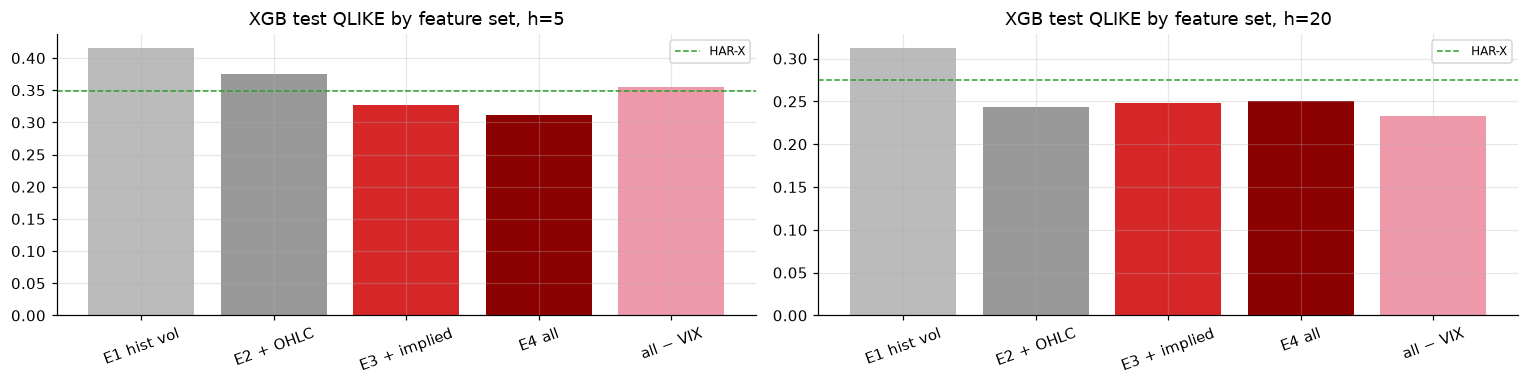

In [15]:
ABL = [("+ OHLC / range / dynamics", "XGB_E2_ohlc", "XGB_E1_hist_vol"),
       ("+ implied vol (XGB)", "XGB_E3_plus_implied", "XGB_E2_ohlc"),
       ("+ volume & momentum", "XGB", "XGB_E3_plus_implied"),
       ("VIX family, XGB (all vs no-VIX)", "XGB", "XGB_E_noVIX"),
       ("VIX family, RF (all vs no-VIX)", "RF", "RF_noVIX"),
       ("VIX², linear (HAR-X vs HAR)", "HAR_X", "HAR")]
abl_rows = []
for h in H:
    t = test[h]
    for label, with_, without in ABL:
        r = E.diebold_mariano(LOSS[h].loc[t, with_], LOSS[h].loc[t, without], h)
        abl_rows.append({"horizon": h, "step": label, "with": with_, "without": without,
                         "QLIKE_with": LOSS[h].loc[t, with_].mean(), "QLIKE_without": LOSS[h].loc[t, without].mean(),
                         "change_%": 100 * (LOSS[h].loc[t, with_].mean() / LOSS[h].loc[t, without].mean() - 1),
                         "p_value": r["p_value"]})
ablation = pd.DataFrame(abl_rows)
ablation["helps?"] = np.select([(ablation.p_value < 0.05) & (ablation["change_%"] < 0),
                                (ablation.p_value < 0.05) & (ablation["change_%"] > 0)],
                               ["yes (significant)", "hurts (significant)"], "not significant")
display(ablation.set_index(["horizon", "step"])[["QLIKE_with", "QLIKE_without", "change_%", "p_value", "helps?"]])

fig, axes = plt.subplots(1, len(H), figsize=(7 * len(H), 3.6))
order = ["XGB_E1_hist_vol", "XGB_E2_ohlc", "XGB_E3_plus_implied", "XGB", "XGB_E_noVIX"]
labels = ["E1 hist vol", "E2 + OHLC", "E3 + implied", "E4 all", "all − VIX"]
for ax, h in zip(np.atleast_1d(axes), H):
    v = LOSS[h].loc[test[h], order].mean()
    ax.bar(labels, v, color=["#bbb", "#999", "tab:red", "darkred", "#e9a"])
    ax.axhline(LOSS[h].loc[test[h], BENCH].mean(), color="tab:green", ls="--", lw=1, label="HAR-X")
    ax.set_title(f"XGB test QLIKE by feature set, h={h}"); ax.tick_params(axis="x", rotation=20); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "ablation"); plt.show()

### 8.1 What drives XGBoost? Grouped SHAP on the test period

The XGB model is refit exactly as in each test fold, and exact TreeSHAP contributions are computed on that fold's test days.

Notebook 2 found 55 near-duplicate feature pairs, so importance is **summed within feature groups**. Credit split between two near-identical estimators says nothing about which one matters.

,share_h5,share_h20
group,,
implied,0.3188,0.2512
range_vol,0.269,0.2422
momentum,0.2669,0.1677
dynamics,0.04095,0.1637
hist_vol,0.02783,0.1091
returns,0.07151,0.04059
volume,0.004927,0.02548


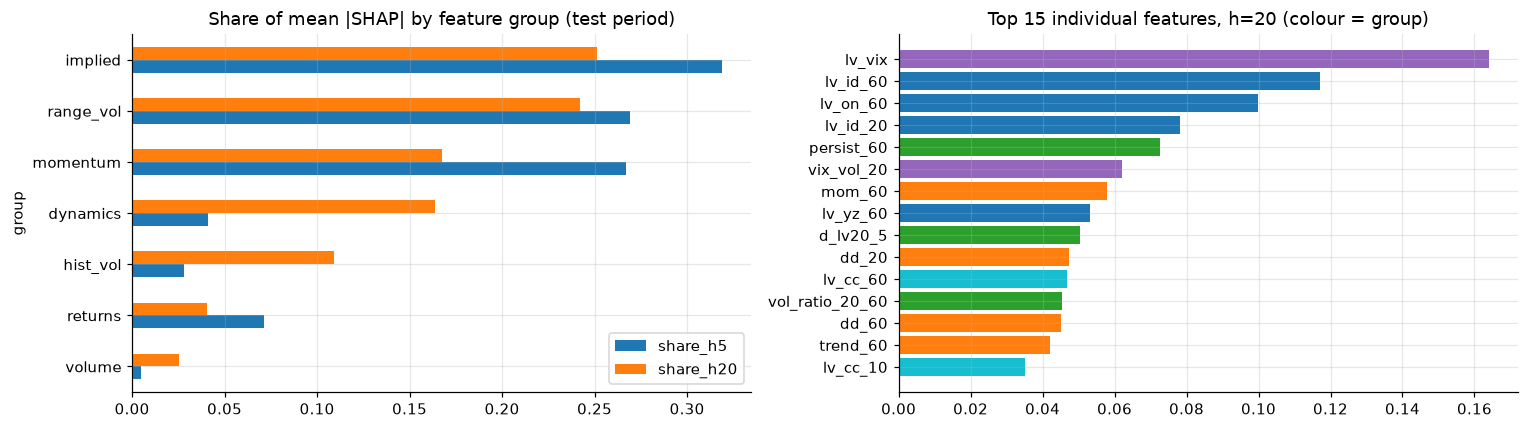

In [16]:
shap_feat, shap_grp = [], []
for h in H:
    folds = make_folds(panel.index, targets[f"label_end_{h}"], cfg["data"]["sample_start"],
                       frozen["test_years"], "test", cfg["data"]["sample_end"])
    cols = feature_sets[frozen["primary_set"]]
    for f in folds:
        mdl = M.make_xgb(frozen["best_params"][f"XGB_h{h}"], frozen["seed"])()
        mdl.fit(X.loc[f.train, cols], targets.loc[f.train, f"rv_logvar_{h}"])
        bf, bg = E.xgb_grouped_shap(mdl, X.loc[f.evaluate, cols], catalog["group"])
        shap_feat.append(bf.rename(f"h{h}_{f.year}"))
        shap_grp.append(bg.rename(f"h{h}_{f.year}"))
shap_groups = pd.concat(shap_grp, axis=1).fillna(0)
shap_features = pd.concat(shap_feat, axis=1).fillna(0)
for h in H:
    c = [x for x in shap_groups.columns if x.startswith(f"h{h}_")]
    shap_groups[f"share_h{h}"] = shap_groups[c].mean(axis=1) / shap_groups[c].mean(axis=1).sum()
display(shap_groups[[f"share_h{h}" for h in H]].sort_values(f"share_h{H[-1]}", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
s = shap_groups[[f"share_h{h}" for h in H]].sort_values(f"share_h{H[-1]}")
s.plot.barh(ax=axes[0]); axes[0].set_title("Share of mean |SHAP| by feature group (test period)")
c20 = [x for x in shap_features.columns if x.startswith(f"h{H[-1]}_")]
top = shap_features[c20].mean(axis=1).sort_values().tail(15)
axes[1].barh(top.index, top.values, color=[{"implied": "tab:purple", "range_vol": "tab:blue", "hist_vol": "tab:cyan",
             "dynamics": "tab:green", "momentum": "tab:orange", "returns": "tab:gray", "volume": "tab:brown"}[catalog.loc[i, "group"]] for i in top.index])
axes[1].set_title(f"Top 15 individual features, h={H[-1]} (colour = group)")
fig.tight_layout(); savefig(fig, "shap"); plt.show()

## 9. Uncertainty: are the 10–90% intervals calibrated?

The quantile model (QGB) predicts the 10th, 50th and 90th percentiles of future variance. If it is calibrated:
- 10% of outcomes fall below q10
- 10% fall above q90
- 80% fall inside the band

**Two tests:**
- **Kupiec:** this assumes independent misses. Overlapping targets make misses cluster, so its p-values are indicative only.
- **Block-bootstrap interval for the hit rate:** this is the valid test.

**Three bands are compared, all using only pre-test information for any calibration:**

| Band | Construction |
|---|---|
| QGB | Raw gradient-boosted quantiles from Notebook 3 |
| QGB + CQR | QGB with each tail shifted by split-conformal calibration (Romano et al. 2019), using QGB's own **validation-period** misses (2019–2022) |
| HAR-X × val-ratio | HAR-X times the 10/90% quantiles of its validation-period ratio RV/forecast. A simple benchmark |

Tree-based quantiles fitted in-sample tend to be too narrow, so raw QGB often undercovers. CQR is the standard distribution-free fix. Both versions are reported so the correction is transparent.

**Does the band carry information?** If interval width tracks real uncertainty, then wider bands should come before larger forecast misses.

In [17]:
cal_rows = []
for h in H:
    t = test[h]
    y = RV[h][t]
    v = ~t
    ratio_val = RV[h][v] / W[h].loc[v, BENCH]
    cq_lo, cq_hi, shifts = E.conformalize_band(W[h].loc[v, "QGB_q10"], W[h].loc[v, "QGB_q90"], RV[h][v],
                                               W[h].loc[t, "QGB_q10"], W[h].loc[t, "QGB_q90"])
    W[h].loc[t, "QGB_CQR_q10"], W[h].loc[t, "QGB_CQR_q90"] = cq_lo, cq_hi
    print(f"h={h}: CQR log-shifts from validation misses: lower {shifts[0]:+.3f}, upper {shifts[1]:+.3f}")
    bands = {"QGB": (W[h].loc[t, "QGB_q10"], W[h].loc[t, "QGB_q50"], W[h].loc[t, "QGB_q90"]),
             "QGB + CQR": (pd.Series(cq_lo, index=y.index), W[h].loc[t, "QGB_q50"], pd.Series(cq_hi, index=y.index)),
             "HAR_X x val-ratio": tuple(W[h].loc[t, BENCH] * ratio_val.quantile(q) for q in (0.1, 0.5, 0.9))}
    for name, (q10, q50, q90) in bands.items():
        below, above = (y < q10).to_numpy(), (y > q90).to_numpy()
        inside = ~(below | above)
        lo_ci = E.block_coverage_ci(inside, block=3 * h, seed=SEED)
        k10, k90 = E.kupiec_pof(below, 0.10), E.kupiec_pof(above, 0.10)
        width = np.log(q90 / q10)
        surprise = np.abs(np.log(y / q50))
        cal_rows.append({"horizon": h, "band": name, "below_q10": below.mean(), "above_q90": above.mean(),
                         "coverage_80": inside.mean(), "cov_ci_lo": lo_ci[0], "cov_ci_hi": lo_ci[1],
                         "kupiec_p_q10": k10["p_value"], "kupiec_p_q90": k90["p_value"],
                         "pinball_q10": E.pinball(y, q10, 0.1), "pinball_q50": E.pinball(y, q50, 0.5),
                         "pinball_q90": E.pinball(y, q90, 0.9),
                         "spearman(width, |miss|)": stats.spearmanr(width, surprise).statistic})
calibration = pd.DataFrame(cal_rows).set_index(["horizon", "band"])
calibration

h=5: CQR log-shifts from validation misses: lower +0.046, upper +0.848
h=20: CQR log-shifts from validation misses: lower +0.114, upper +1.115


below_q10  above_q90  coverage_80  cov_ci_lo  cov_ci_hi  kupiec_p_q10  kupiec_p_q90  pinball_q10  pinball_q50  pinball_q90  \
horizon band                                                                                                                                            
5       QGB                   0.1144      0.117       0.7686     0.7207     0.8125        0.1983        0.1287     0.001894      0.00667     0.006157   
        QGB + CQR             0.1064    0.01729       0.8763     0.8418     0.9082        0.5632     4.222e-20     0.001879      0.00667      0.01007   
        HAR_X x val-ratio    0.02527     0.1835       0.7912     0.7287     0.8444     8.875e-16     4.313e-12     0.002066     0.007728     0.006266   
20      QGB                   0.1396     0.0758       0.7846     0.6303     0.9189     0.0005823       0.02138     0.001914      0.00618     0.007354   
        QGB + CQR             0.0984    0.02128       0.8803     0.7779     0.9601        0.8838      8.17e-18     0.001775      0.00618      0.01256   
        HAR_X x val-ratio          0     0.0891       0.9109     0.8191     0.9934     2.453e-36        0.3107      0.00186     0.006436      0.00671   

                           spearman(width, |miss|)  
horizon band                                        
5       QGB                                 0.1965  
        QGB + CQR                           0.1965  
        HAR_X x val-ratio                 -0.03538  
20      QGB                               -0.07207  
        QGB + CQR                         -0.07207  
        HAR_X x val-ratio                  0.04365

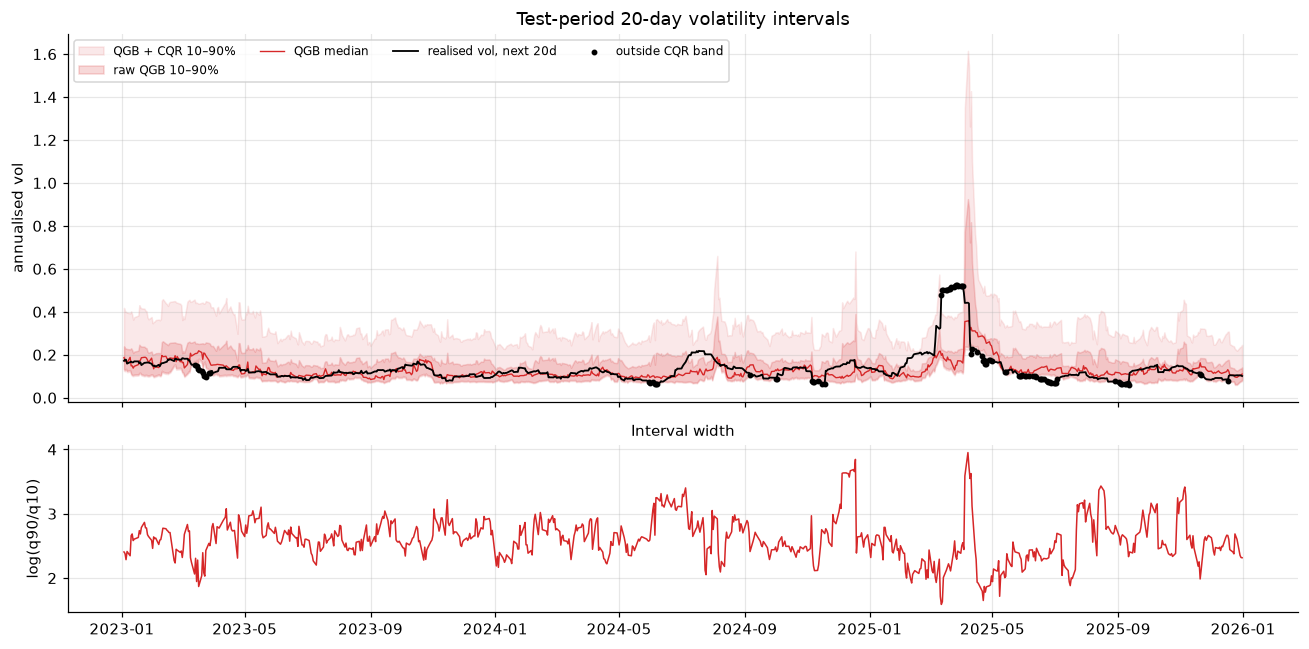

80% band coverage by regime (test):


,h=5 raw,h=5 CQR,h=20 raw,h=20 CQR
regime,,,,
low,0.7593,0.8951,0.8148,0.9136
mid,0.7851,0.8915,0.8553,0.934
high,0.7167,0.7917,0.4667,0.625


In [18]:
h = H[-1]
t = test[h]
w = W[h].loc[t]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax = axes[0]
ax.fill_between(w.index, np.sqrt(w.QGB_CQR_q10), np.sqrt(w.QGB_CQR_q90), color="tab:red", alpha=0.10, label="QGB + CQR 10–90%")
ax.fill_between(w.index, np.sqrt(w.QGB_q10), np.sqrt(w.QGB_q90), color="tab:red", alpha=0.18, label="raw QGB 10–90%")
ax.plot(w.index, np.sqrt(w.QGB_q50), color="tab:red", lw=0.9, label="QGB median")
ax.plot(w.index, np.sqrt(RV[h][t]), color="k", lw=1.2, label=f"realised vol, next {h}d")
out = (RV[h][t] > w.QGB_CQR_q90) | (RV[h][t] < w.QGB_CQR_q10)
ax.scatter(w.index[out], np.sqrt(RV[h][t][out]), s=8, color="k", zorder=3, label="outside CQR band")
ax.set_ylabel("annualised vol"); ax.legend(ncol=4, fontsize=8)
ax.set_title(f"Test-period {h}-day volatility intervals")
axes[1].plot(w.index, np.log(w.QGB_CQR_q90 / w.QGB_CQR_q10), color="tab:red", lw=1)
axes[1].set_ylabel("log(q90/q10)"); axes[1].set_title("Interval width", fontsize=10)
fig.tight_layout(); savefig(fig, "intervals"); plt.show()

cov_reg = []
for hh in H:
    tt = test[hh]
    y = RV[hh][tt]; ww = W[hh].loc[tt]
    rg = regimes.reindex(y.index)
    for nm, a_, b_ in [("raw", "QGB_q10", "QGB_q90"), ("CQR", "QGB_CQR_q10", "QGB_CQR_q90")]:
        ins = ((y >= ww[a_]) & (y <= ww[b_])).groupby(rg).mean().reindex(["low", "mid", "high"])
        cov_reg.append(ins.rename(f"h={hh} {nm}"))
print("80% band coverage by regime (test):")
pd.concat(cov_reg, axis=1)

## 10. Verdicts on H1 and H2

In [19]:
def p_of(h, comp):
    r = pairs[(pairs.horizon == h) & (pairs.comparison == comp)].iloc[0]
    return r.QLIKE_ratio, r.p_value

verdict = []
for h in H:
    rx, px = p_of(h, "XGB vs HAR_X")
    rg, pg = p_of(h, "XGB vs GJR")
    in_mcs = set(mcs[(mcs.horizon == h) & (mcs.loss == "QLIKE") & mcs.in_MCS].model)
    best = scorecard[scorecard.horizon == h].set_index("model")["QLIKE"].idxmin()
    if px < 0.05 and rx < 1:
        h1 = "SUPPORTED: XGB significantly beats HAR-X"
    elif px < 0.05 and rx > 1:
        h1 = "REJECTED: XGB is significantly worse than HAR-X"
    else:
        h1 = "NOT SUPPORTED: no significant difference between XGB and HAR-X"
    p_h2 = h2_test.loc[(h, "test"), "p_value(equal across regimes)"]
    rd = regime_dm[(regime_dm.horizon == h) & (regime_dm.split == "test")]
    if p_h2 < 0.05:
        h2 = f"SUPPORTED: XGB's edge over HAR-X differs across regimes (joint p = {p_h2:.3f})"
    elif np.sign(rd["XGB/HAR_X"] - 1).nunique() > 1:
        h2 = f"NOT SUPPORTED: point estimates change sign across regimes, but jointly insignificant (p = {p_h2:.3f})"
    else:
        h2 = f"NOT SUPPORTED: same ordering in every regime (joint p = {p_h2:.3f})"
    verdict.append({"horizon": h, "best_test_QLIKE": best, "XGB/HAR_X": rx, "p(XGB vs HAR_X)": px,
                    "XGB/GJR": rg, "p(XGB vs GJR)": pg, "MCS_90 (QLIKE)": ", ".join(sorted(in_mcs)),
                    "H1": h1, "H2": h2})
verdicts = pd.DataFrame(verdict).set_index("horizon")
with pd.option_context("display.max_colwidth", 80):
    display(verdicts.T)

horizon,5,20
best_test_QLIKE,XGB,ENS_EQ
XGB/HAR_X,0.8938,0.9127
p(XGB vs HAR_X),0.2081,0.5613
XGB/GJR,0.8596,0.9884
p(XGB vs GJR),0.04323,0.9318
MCS_90 (QLIKE),"ENS_EQ, ENS_REGIME, ENS_TRAIL, HAR_X, RF, XGB","EGARCH, ENS_EQ, ENS_TRAIL, GJR, HAR_X, RF, XGB"
H1,NOT SUPPORTED: no significant difference between XGB and HAR-X,NOT SUPPORTED: no significant difference between XGB and HAR-X
H2,NOT SUPPORTED: same ordering in every regime (joint p = 0.703),"NOT SUPPORTED: point estimates change sign across regimes, but jointly insig..."


## 11. Save outputs

In [20]:
dm_all.to_csv(RES / "dm_tests.csv", index=False)
pairs.to_csv(RES / "dm_pairs.csv", index=False)
mcs.to_csv(RES / "mcs.csv", index=False)
mz.to_csv(RES / "mincer_zarnowitz.csv", index=False)
by_year.to_csv(RES / "test_by_year.csv")
regime_losses.to_csv(RES / "regime_losses.csv", index=False)
regime_dm.to_csv(RES / "regime_dm.csv", index=False)
h2_test.to_csv(RES / "h2_joint_test.csv")
stress.to_csv(RES / "stress_losses.csv")
ablation.to_csv(RES / "ablation.csv", index=False)
shap_groups.to_csv(RES / "shap_groups.csv")
calibration.to_csv(RES / "interval_calibration.csv")
verdicts.to_csv(RES / "verdicts_h1_h2.csv")

findings = {
    "frozen_config_sha256": FROZEN_HASH[:16],
    "test_scorings_logged": int(len(scoring_log)), "distinct_configs_scored": int(n_configs),
    **{f"h{h}_best_model": verdicts.loc[h, "best_test_QLIKE"] for h in H},
    **{f"h{h}_XGB_over_HARX": round(float(verdicts.loc[h, "XGB/HAR_X"]), 3) for h in H},
    **{f"h{h}_p_XGB_vs_HARX": round(float(verdicts.loc[h, "p(XGB vs HAR_X)"]), 4) for h in H},
    **{f"h{h}_MCS90": verdicts.loc[h, "MCS_90 (QLIKE)"] for h in H},
    **{f"h{h}_H1": verdicts.loc[h, "H1"] for h in H},
    **{f"h{h}_H2": verdicts.loc[h, "H2"] for h in H},
    **{f"h{h}_VIX_helps_XGB_pct": round(float(ablation[(ablation.horizon == h) & (ablation.step.str.startswith("VIX family, XGB"))]["change_%"].iloc[0]), 1) for h in H},
    **{f"h{h}_QGB_coverage80": round(float(calibration.loc[(h, "QGB"), "coverage_80"]), 3) for h in H},
    **{f"h{h}_QGB_CQR_coverage80": round(float(calibration.loc[(h, "QGB + CQR"), "coverage_80"]), 3) for h in H},
    "top_shap_group_h20": shap_groups[f"share_h{H[-1]}"].idxmax(),
}
(OUT / "nb04_findings.json").write_text(json.dumps(findings, indent=2, default=str))
meta4 = {"notebook": "04_evaluation", "data_mode": DATA_MODE, "frozen_config_sha256": FROZEN_HASH,
         "inputs_sha256": {"oos_forecasts.parquet": meta3["outputs_sha256"]["oos_forecasts.parquet"]},
         "outputs_sha256": {"ensembles.parquet": acquire.sha256(OUT / "ensembles.parquet")}}
(OUT / "nb04_meta.json").write_text(json.dumps(meta4, indent=2))
pd.Series(findings, name="value").to_frame()

,value
frozen_config_sha256,2d139937c8523977
test_scorings_logged,1
distinct_configs_scored,1
h5_best_model,XGB
h20_best_model,ENS_EQ
h5_XGB_over_HARX,0.894
h20_XGB_over_HARX,0.913
h5_p_XGB_vs_HARX,0.2081
h20_p_XGB_vs_HARX,0.5613
h5_MCS90,"ENS_EQ, ENS_REGIME, ENS_TRAIL, HAR_X, RF, XGB"


**How to write this up (report Sections 6–7):**

1. **Lead with the scorecard and the forest plot, then the MCS.** "Model X is in the 90% MCS under both QLIKE and MSE" is a stronger claim than any single ranking.
2. **State H1 exactly as the verdict table gives it, including if it is a null result.** "XGBoost does not significantly beat HAR-X once implied volatility is included" is a publishable finding, and it is consistent with much of the literature.
3. **Use the ablation to explain *why*.** If VIX accounts for most of the gain, the economic story is that option markets already price most forecastable variance. This leads directly into Notebook 5's question: is the *remainder*, the gap between forecast and implied variance, tradable?
4. **Report the Mincer-Zarnowitz slopes.** b < 1 for ML would indicate over-reaction to features in calm periods.
5. **Report interval coverage with its bootstrap interval, not the Kupiec p-value alone.** If raw QGB undercovers and CQR restores coverage, say so. That is the honest version of the uncertainty contribution, and Notebook 5 sizes positions with the CQR band.
6. **On the MCS:** a large confidence set means the test cannot separate the models over three years of data. That is a statement about statistical power, not proof that the models are equal.

**Next: Notebook 5.** It covers the variance-risk-premium study (H3, H4), and the delta-hedged straddle backtest if options data is available (H5).